In [18]:
import utils
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
from ipywidgets import interact
import ipywidgets as widgets
import matplotlib.gridspec as gridspec
from scipy.stats import norm, lognorm
from scipy.stats import kstest
import matplotlib.dates as mdates


## Filepaths

In [2]:
path_TA00007_data = "" 
path_TA00251_data = "" 
path_tahmo_meta = "" 
path_imerg_daily = "" 
path_imerg_halfhourly = "" 
path_sentinel1_data = "" 

### Load TAHMO data

In [3]:
TA00007 = pd.read_csv(path_TA00007_data, index_col=0, parse_dates=True)
TA00251 = pd.read_csv(path_TA00251_data, index_col=0, parse_dates=True)

In [4]:
TA00007.loc[TA00007['final_quality_flag'] < 1, 'precip_mm'] = np.nan
TA00251.loc[TA00251['final_quality_flag'] < 1, 'precip_mm'] = np.nan

TA00007_monthly = pd.DataFrame(TA00007['precip_mm'].resample('ME').sum())
TA00251_monthly = pd.DataFrame(TA00251['precip_mm'].resample('ME').sum())


In [5]:
TA00007_monthly['month'] = TA00007_monthly.index.month
TA00251_monthly['month'] = TA00251_monthly.index.month

In [6]:
TA00007_reindex = TA00007_monthly[TA00007_monthly.index.year.isin([2018, 2019, 2020, 2021, 2023,])]
TA00251_reindex = TA00251_monthly[TA00251_monthly.index.year.isin([2018, 2020, 2021,2022, 2023, 2025])]

### Load IMERG data

In [7]:
stations = ["TA00007", "TA00251"]
 
meta = pd.read_csv(path_tahmo_meta, index_col=0)
coords = {s: (meta.loc[s].latitude, meta.loc[s].longitude) for s in stations}
reindex_idx = {"TA00007": TA00007_reindex.index, "TA00251": TA00251_reindex.index}
 
 
def point(da, lat, lon):
    """Nearest-pixel time series as a single-column DataFrame (loads only that pixel)."""
    return da.sel(lat=lat, lon=lon, method='nearest').to_dataframe()[['precipitation']]
 
 
imerg_long = xr.open_mfdataset(path_imerg_daily)['precipitation'] #Longer IMERG record than HH downloads
 
imerg_month, imerg_hourly, imerg_daily = {}, {}, {}
 
for s in stations:
    lat, lon = coords[s]
 
    imerg_month[s] = point(imerg_long, lat, lon).resample('ME').sum()
 
    hh = point(xr.open_mfdataset(path_imerg_halfhourly)['precipitation'], lat, lon)
    imerg_hourly[s] = hh.resample('h').mean()

    imerg_daily[s] = hh.resample('24h', offset='18h30min', label='right', closed='right').mean() * 24
 
 
imerg_ta00007_month, imerg_ta00251_month = imerg_month["TA00007"], imerg_month["TA00251"]
imerg_ta00007_hourly, imerg_ta00251_hourly = imerg_hourly["TA00007"], imerg_hourly["TA00251"]
imerg_ta00007_daily, imerg_ta00251_daily = imerg_daily["TA00007"], imerg_daily["TA00251"]

## Figure 4

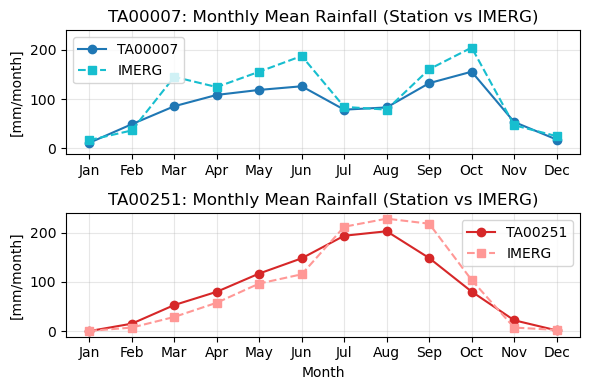

In [8]:
# Monthly means


imerg_ta00251_month['month'] = imerg_ta00251_month.index.month
imerg_ta00007_month['month'] = imerg_ta00007_month.index.month


m1_station = TA00007_reindex.groupby('month').mean()
m1_imerg   = imerg_ta00007_month.groupby('month').mean()

m2_station = TA00251_reindex.groupby('month').mean()
m2_imerg   = imerg_ta00251_month.groupby('month').mean()

fig, axes = plt.subplots(2, 1, figsize=(6, 4), sharey=True)

months = range(1, 13)
month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']

# TA00007 → blue
c1, c2 = "#1f77b4", "#17becf"
# TA00251 → red
c3, c4 = "#d62728", "#ff9896"

# ---- TA00007 ----
axes[0].plot(months, m1_station, marker='o', color=c1, label='TA00007')
axes[0].plot(months, m1_imerg, marker='s', linestyle='--', color=c2, label='IMERG')

# ---- TA00251 ----
axes[1].plot(months, m2_station, marker='o', color=c3, label='TA00251')
axes[1].plot(months, m2_imerg, marker='s', linestyle='--', color=c4, label='IMERG')

# Formatting
for ax in axes:
    ax.set_xticks(months)
    ax.set_xticklabels(month_labels)
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlabel('Month')
axes[0].set_ylabel('[mm/month]')
axes[1].set_ylabel('[mm/month]')
axes[0].set_title('TA00007: Monthly Mean Rainfall (Station vs IMERG)')
axes[1].set_title('TA00251: Monthly Mean Rainfall (Station vs IMERG)')
plt.tight_layout()


### Figures 5 / 6


In [9]:
###  Store absolute backscatter of all fields in dictionary
TA = 'TA00007'
path_to_sentinel_fields = [f'{path_sentinel1_data}/{TA}_collection/field{i}_gee/' for i in range(1, 17)] # All fields

absolute_s1_backscatter_fields = {}
for i in range(len(path_to_sentinel_fields)):
    data = utils.create_xarray_gee_dataset_from_folder(path_to_sentinel_fields[i])
    data = data.where(data!=0,np.nan)
    absolute_s1_backscatter_fields[f'Field{i+1}'] = data


In [10]:
## Compute pixel-wise relative backscatter for every field (VV, VH and VV/VH)
percentile_fields_dic = {}
for field, data in absolute_s1_backscatter_fields.items():
    percentile_field = utils.compute_percentile_dataset(data.where(data['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), min_month=1, max_month=12)
    percentile_fields_dic[field] = percentile_field

vhpercentile_fields_dic = {}
for field, data in absolute_s1_backscatter_fields.items():
    percentile_field = utils.compute_percentile_dataset(data.where(data['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VH', min_month=1, max_month=12)
    vhpercentile_fields_dic[field]  = percentile_field

vvvhpercentile_fields_dic = {}
for field, data in absolute_s1_backscatter_fields.items():
    percentile_field = utils.compute_percentile_dataset(data.where(data['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VV-VH', min_month=1, max_month=12)
    vvvhpercentile_fields_dic[field]  = percentile_field

In [11]:
## Split data for fields located in two S-1 swaths, and merge two climatologies
double_acquisitions = []
for station, data in percentile_fields_dic.items():
    if len(data.time) >500:
        double_acquisitions.append(station)
base_index = absolute_s1_backscatter_fields['Field2']['data'][:,2].where(absolute_s1_backscatter_fields['Field2']['data'][:,2].mean(dim=['x','y'])>40, drop=True).time


for field in double_acquisitions:
    field_data_baseindex = absolute_s1_backscatter_fields[field].drop_duplicates(dim='time').sel(time=list(np.intersect1d(absolute_s1_backscatter_fields[field].time.values, base_index.values)))
    
    mask = ~absolute_s1_backscatter_fields[field].time.isin(base_index.values)
    field_data_extra = absolute_s1_backscatter_fields[field].sel(time=mask)
#### VV
    
    percentile_field_baseindex = utils.compute_percentile_dataset(field_data_baseindex.where(field_data_baseindex['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), min_month=1, max_month=12)
    percentile_field_extra = utils.compute_percentile_dataset(field_data_extra.where(field_data_extra['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), min_month=1, max_month=12)
    
    percentile_fields_dic[field] = percentile_field_baseindex.merge(percentile_field_extra,join='outer', compat='no_conflicts')
#### VH

    percentile_field_baseindex = utils.compute_percentile_dataset(field_data_baseindex.where(field_data_baseindex['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VH', min_month=1, max_month=12)
    percentile_field_extra = utils.compute_percentile_dataset(field_data_extra.where(field_data_extra['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VH', min_month=1, max_month=12)
    
    vhpercentile_fields_dic[field] = percentile_field_baseindex.merge(percentile_field_extra,join='outer', compat='no_conflicts')
#### VV/VH
    percentile_field_baseindex = utils.compute_percentile_dataset(field_data_baseindex.where(field_data_baseindex['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VV-VH', min_month=1, max_month=12)
    percentile_field_extra = utils.compute_percentile_dataset(field_data_extra.where(field_data_extra['time.year'] >2015, drop=True).sortby('time').drop_duplicates(dim='time'), pol='VV-VH', min_month=1, max_month=12)
    
    vvvhpercentile_fields_dic[field] = percentile_field_baseindex.merge(percentile_field_extra,join='outer', compat='no_conflicts')

Text(0.5, 1.09, 'TA00007: Sentinel-1 Backscatter Time Series and Pixel-wise Climatology (Field2+ Field5)')

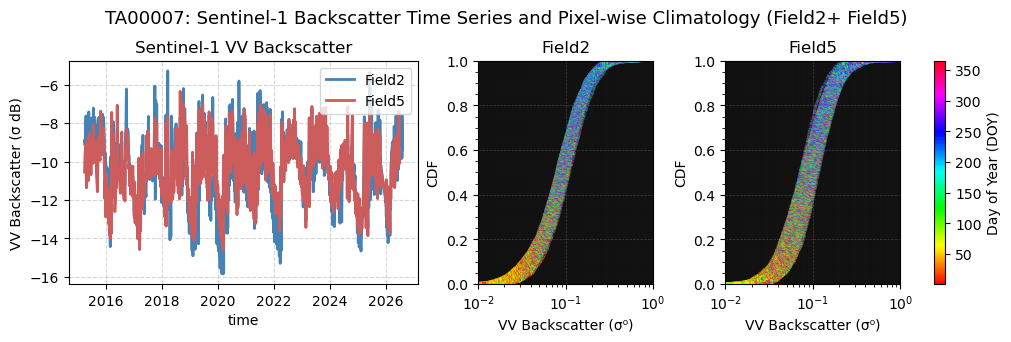

In [12]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(10, 3),
    gridspec_kw={'width_ratios': [2, 1, 1]},  
    constrained_layout=True
)

# =========================
# LEFT: Time series 
# =========================
ax_ts = axes[0]

# Force white/default style manually
ax_ts.set_facecolor('white')
for spine in ax_ts.spines.values():
    spine.set_color('black')

vv_ts1 = absolute_s1_backscatter_fields['Field2']['data'][:, 0].mean(dim=['x', 'y'])
vv_ts2 = absolute_s1_backscatter_fields['Field5']['data'][:, 0].mean(dim=['x', 'y'])

vv_ts1.plot(ax=ax_ts, linewidth=2, color='steelblue', label='Field2')
vv_ts2.plot(ax=ax_ts, linewidth=2, color='indianred', label='Field5')

ax_ts.set_title('Sentinel-1 VV Backscatter', color='black')
ax_ts.set_ylabel('VV Backscatter (σ dB)', color='black')
ax_ts.tick_params(colors='black')
ax_ts.grid(True, linestyle='--', alpha=0.5)
ax_ts.legend()

# =========================
# RIGHT: CDFs (DARK)
# =========================
cmap = plt.get_cmap("hsv")
norm_scale = Normalize(vmin=1, vmax=365)

field_names = ["Field2", "Field5"]

for ax, field_name in zip(axes[1:], field_names):
    ax.set_facecolor('#111111')

    ds = absolute_s1_backscatter_fields[field_name]

    for x in range(len(ds.x)):
        for y in range(len(ds.y)):
            if not np.isnan(ds['data'][:, 0, y, x]).any():
                data = 10**(ds['data'][:, 0, y, x].to_dataframe()/10) #Convert from dB to linear scale

                data['DOY'] = data.index.dayofyear
                sorted_data = data.sort_values(by='data')
                cdf = np.arange(1, len(sorted_data) + 1) / len(sorted_data)

                points = np.array([sorted_data['data'].values, cdf]).T.reshape(-1, 1, 2)
                segments = np.concatenate([points[:-1], points[1:]], axis=1)

                colors = cmap(norm_scale(sorted_data['DOY'].values))
                lc = LineCollection(segments, colors=colors, linewidth=2, alpha=0.7)
                ax.add_collection(lc)

    ax.set_title(field_name)

    ax.set_xscale('log')
    ax.set_xlim(1e-2, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("VV Backscatter (σ⁰)")
    ax.set_ylabel("CDF")
    ax.grid(True, which='major', color='white', linestyle='--', linewidth=0.5, alpha=0.2)
    ax.grid(True, which='minor', color='white', linestyle=':', linewidth=0.3, alpha=0.1)
    ax.minorticks_on()

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[1:], orientation='vertical')
cbar.set_label("Day of Year (DOY)")
fig.suptitle(
    "TA00007: Sentinel-1 Backscatter Time Series and Pixel-wise Climatology (Field2+ Field5)",
    fontsize=13,
    y=1.09
)



## Figures 7/8

In [16]:

station_daily = TA00007['precip_mm'].resample('D', offset='18H30min', label='right', closed='right').sum() #Or TA00251
station_daily_cumsum = station_daily.cumsum()
station_name = 'TA00007'
station_reindex = pd.DataFrame(station_daily_cumsum.loc[
    station_daily_cumsum.index.normalize().isin(
        pd.to_datetime(percentile_fields_dic[field].time).normalize()
    )
].diff())

imerg_location = imerg_ta00007_daily ## Select IMERG data here

fields = ["Field2", "Field5"] 
field_top = fields[0]
field_bottom = fields[1]

plot_imerg = True

times = percentile_fields_dic[fields[0]].where(
    percentile_fields_dic[fields[0]]['time.year'] > 2017,
    drop=True
).time.values

@interact(t=widgets.IntSlider(min=1, max=len(times)-2, step=1, value=1))
def plot_slider(t):

    fig = plt.figure(figsize=(13, 6))

    gs = gridspec.GridSpec(
        4, 5,   
        height_ratios=[0.06, 1, 0.06, 1],
        width_ratios=[1, 1, 1, 0.35, 1.6],  
        hspace=0.4,
        wspace=0.05
    )


    time_indices = [t-1, t, t+1]

    ds_top = percentile_fields_dic[field_top]
    ds_bottom = percentile_fields_dic[field_bottom]

    # =========================
    # --- Title ---
    # =========================
    ax_title_top = fig.add_subplot(gs[0, :3])
    ax_title_top.axis('off')
    ax_title_top.text(
    0.5, 0.2, field_top,
    ha='center', va='center',
    fontsize=13, weight='bold'
    )


    # =========================
    # --- ROW 1 ---
    # =========================
    for i, ti in enumerate(time_indices):
        ax = fig.add_subplot(gs[1, i])

        da = ds_top["vv_percentile"].sel(time=times[ti])
        da.plot(ax=ax, vmin=0, vmax=1, cmap='RdBu', add_colorbar=(i==2))

        date_str = pd.to_datetime(times[ti]).strftime("%Y-%m-%d")
        ax.set_title(date_str, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")

    # =========================
    # --- PRECIP ---
    # =========================
    ax_precip = fig.add_subplot(gs[1, 4])

    t_start = times[t-1]
    t_end   = times[t+1] + np.timedelta64(1, 'D')

    tah = station_daily.loc[t_start:t_end]
    ax_precip.plot(tah.index, tah.values, marker='o', linewidth=1, label=station_name)
    ax_precip.set_ylabel('mm/day')
    if plot_imerg:
        imerg = imerg_location.loc[t_start:t_end]
        ax_precip.plot(imerg.index, imerg.values, marker='o', linewidth=1, alpha=0.6, label='IMERG')

    ax_precip.set_title("Precipitation", fontsize=12)
    ax_precip.set_ylim(0, 50)
    ax_precip.tick_params(axis='x', rotation=45, labelsize=8)
    ax_precip.axvline(times[t-1]+ np.timedelta64(19, 'h'), linestyle='--', c='k', alpha=0.3)
    ax_precip.axvline(times[t]+ np.timedelta64(19, 'h'), linestyle='--', c='k', alpha=0.3)
    ax_precip.axvline(times[t+1]+ np.timedelta64(19, 'h'), linestyle='--', c='k', alpha=0.3, label='S-1 Acquisition')
    ax_precip.legend()
    # =========================
    # --- ROW 2---
    # =========================
    ax_title_bottom = fig.add_subplot(gs[2, :3])
    ax_title_bottom.axis('off')
    ax_title_bottom.text(
    0.5, 0.2, field_bottom,
    ha='center', va='center',
    fontsize=13, weight='bold'
)


    # =========================
    # --- ROW 3: FIELD5 MAPS ---
    # =========================
    for i, ti in enumerate(time_indices):
        ax = fig.add_subplot(gs[3, i])

        da = ds_bottom["vv_percentile"].sel(time=times[ti])
        da.plot(ax=ax, vmin=0, vmax=1, cmap='RdBu', add_colorbar=(i==2))

        date_str = pd.to_datetime(times[ti]).strftime("%Y-%m-%d")
        ax.set_title(date_str, fontsize=10)

        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")

        
    # =========================
    # --- PDF BLOCK ---
    # =========================
    gs_pdf = gridspec.GridSpecFromSubplotSpec(
        3, 3,
        subplot_spec=gs[3, 4],
        height_ratios=[0.12, 1, 1],  # 👈 was 0.2 → too big
        hspace=0.4,
        wspace=0.2
    )
    ax_pdf_frame = fig.add_subplot(gs[3, 4])
    ax_pdf_frame.axis('off')

    # PDF title row 
    ax_pdf_title = fig.add_subplot(gs_pdf[0, :])
    ax_pdf_title.axis('off')
    ax_pdf_title.set_title("PDFs (Field2 top, Field5 bottom)", fontsize=11, pad=2)
    fig.text(
        0.78, 0.05, "VV percentile",
        ha='center', va='center',
        fontsize=10
    )

    def plot_pdf(ax, data, title, is_bottom_row=False, is_left_col=False):
        values = data.flatten()
        values = values[~np.isnan(values)]
    
        mu, sigma = np.mean(values), np.std(values)
        x_axis = np.linspace(values.min(), values.max(), 300)
    
        ax.hist(values, bins=30, density=True, alpha=0.6)
        ax.plot(x_axis, norm.pdf(x_axis, mu, sigma), linewidth=1.5)
    
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 4)
        ax.set_title(title, fontsize=12)
    
        if not is_bottom_row:
            ax.set_xticks([])
        else:
            ax.tick_params(axis='x', labelsize=7)
    
        if not is_left_col:
            ax.set_yticks([])
        else:
            ax.tick_params(axis='y', labelsize=7)

    # FIELD a PDFs
    for i, ti in enumerate(time_indices):
        ax = fig.add_subplot(gs_pdf[1, i])
        data = ds_top["vv_percentile"].sel(time=times[ti]).values
        date_str = pd.to_datetime(times[ti]).strftime("%y-%m-%d")
        plot_pdf(ax, data, date_str,
         is_bottom_row=False,
         is_left_col=(i == 0))

    # FIELD b PDFs
    for i, ti in enumerate(time_indices):
        ax = fig.add_subplot(gs_pdf[2, i])
        data = ds_bottom["vv_percentile"].sel(time=times[ti]).values
        date_str = pd.to_datetime(times[ti]).strftime("%y-%m-%d")
        plot_pdf(ax, data, date_str,
         is_bottom_row=True,
         is_left_col=(i == 0))

        ax.set_title('')


    plt.show()

C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\2406189132.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  station_daily = TA00007['precip_mm'].resample('D', offset='18H30min', label='right', closed='right').sum() #Or TA00251


interactive(children=(IntSlider(value=1, description='t', max=784, min=1), Output()), _dom_classes=('widget-in…

## Figure 9


C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\3811459572.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  TA00007_hourly = TA00007['precip_mm'].resample('H').sum()


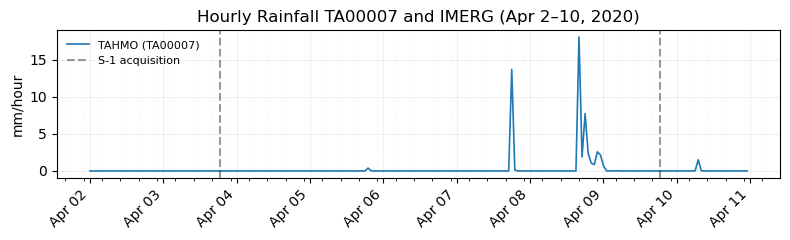

In [19]:
fig, ax = plt.subplots(figsize=(8, 2.5))

day_begin = '2020-04-02'
day_end = '2020-04-10'

TA00007_hourly = TA00007['precip_mm'].resample('H').sum()

# Plot data
ax.plot(TA00007_hourly.loc[day_begin:day_end].index,
        TA00007_hourly.loc[day_begin:day_end].values,
        linewidth=1.2, label='TAHMO (TA00007)')

# S-1 acquisition lines
for i, tline in enumerate(['2020-04-03 18:30', '2020-04-09 18:30']):
    ax.axvline(pd.to_datetime(tline),
               color='black', linestyle='--', alpha=0.4,
               label='S-1 acquisition' if i == 0 else None)

ax.set_ylabel('mm/hour')
ax.set_title("Hourly Rainfall TA00007 and IMERG (Apr 2–10, 2020)")

ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

ax.xaxis.set_minor_locator(mdates.HourLocator(interval=6))

plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

ax.grid(True, which='major', linestyle='-', alpha=0.2)
ax.grid(True, which='minor', linestyle=':', alpha=0.1)

ax.legend(frameon=False, fontsize=8, loc='upper left')

plt.tight_layout()

plt.show()

C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\4187815227.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  TA00251_hourly = TA00251['precip_mm'].resample('H').sum()


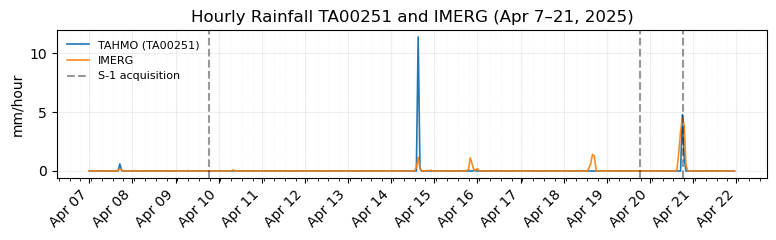

In [20]:
fig, ax = plt.subplots(figsize=(8, 2.5))

day_begin = '2025-04-07'
day_end = '2025-04-21'

TA00251_hourly = TA00251['precip_mm'].resample('H').sum()

#  Plot data
ax.plot(TA00251_hourly.loc[day_begin:day_end].index, TA00251_hourly.loc[day_begin:day_end].values, linewidth=1.2, label='TAHMO (TA00251)')
ax.plot(imerg_ta00251_hourly.loc[day_begin:day_end].index, imerg_ta00251_hourly.loc[day_begin:day_end].values,
        linewidth=1.2, alpha=0.9, label='IMERG')

# S-1 acquisition lines
for i, tline in enumerate(['2025-04-09 18:30', '2025-04-19 18:30', '2025-04-20 18:30']):
    ax.axvline(pd.to_datetime(tline),
               color='black', linestyle='--', alpha=0.4,
               label='S-1 acquisition' if i == 0 else None)

ax.set_ylabel('mm/hour')
ax.set_title("Hourly Rainfall TA00251 and IMERG (Apr 7–21, 2025)")

ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

ax.xaxis.set_minor_locator(mdates.HourLocator(interval=6))

plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

ax.grid(True, which='major', linestyle='-', alpha=0.2)
ax.grid(True, which='minor', linestyle=':', alpha=0.1)

ax.legend(frameon=False, fontsize=8, loc='upper left')

plt.tight_layout()

plt.show()

## Figures 10 / 11

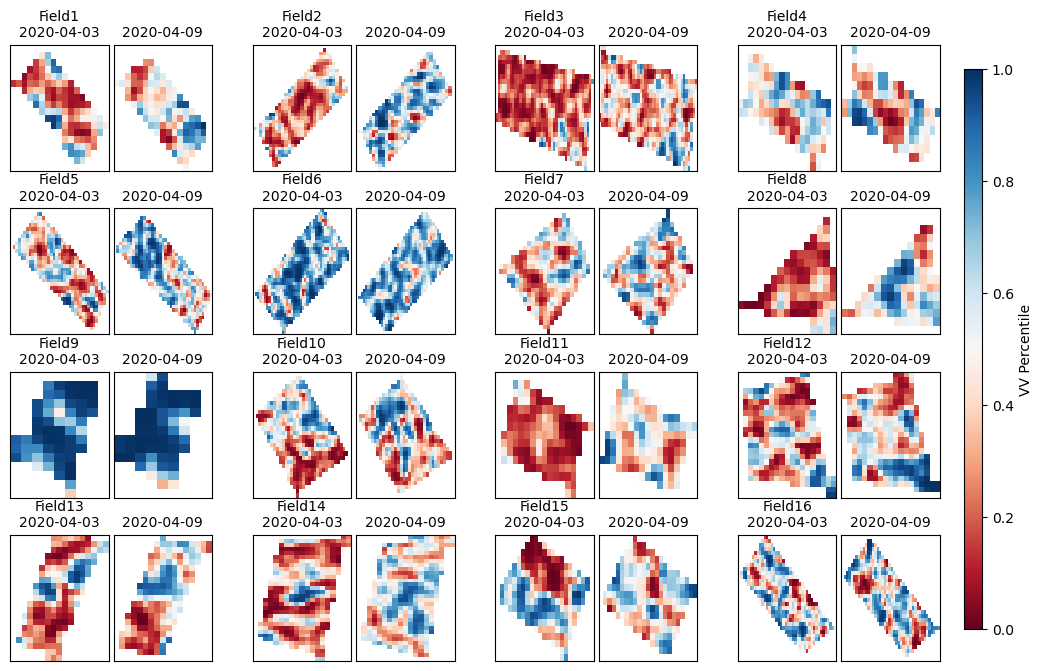

In [21]:
fig = plt.figure(figsize=(12, 8))

# Outer grid: 4x4
gs_outer = gridspec.GridSpec(4, 4, wspace=0.2, hspace=0.3)

times_sel = ['2020-04-03', '2020-04-09']

for i in range(16):
    field_name = f'Field{i+1}'
    ds = percentile_fields_dic[field_name]

    row = i // 4
    col = i % 4

    #  INNER GRID
    gs_inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=gs_outer[row, col],
        wspace=0.05,
        hspace=0.45
    )

    for j, t_str in enumerate(times_sel):
        ax = fig.add_subplot(gs_inner[0, j])

        da = ds['vv_percentile'].sel(time=t_str, method='ffill')
        da.plot(ax=ax, vmin=0, vmax=1, cmap='RdBu', add_colorbar=False)

        # Titles
        if j == 0:
            ax.set_title(f"{field_name}\n{pd.to_datetime(
                    ds['vv_percentile'].sel(time=t_str, method='ffill').time.values
                ).strftime('%Y-%m-%d')}", fontsize=10)
        else:
            ax.set_title(
                pd.to_datetime(
                    ds['vv_percentile'].sel(time=t_str, method='ffill').time.values
                ).strftime('%Y-%m-%d'),
                fontsize=10
            )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")

# Shared colorbar
cax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
sm = plt.cm.ScalarMappable(cmap='RdBu', norm=plt.Normalize(0, 1))
fig.colorbar(sm, cax=cax, label='VV Percentile')

plt.show()

## Figure 12

C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\525773099.py:9: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  TA00007_daily = TA00007['precip_mm'].resample('D', offset='18H30min', label='right', closed='right').sum()
C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\525773099.py:31: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  imerg_field2 = imerg_dict[(1,1)].resample(
C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\525773099.py:35: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  imerg_field11 = imerg_dict[(0,2)].resample(
C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\525773099.py:39: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  imerg_field14 = imerg_dict[(2,0)].resample(


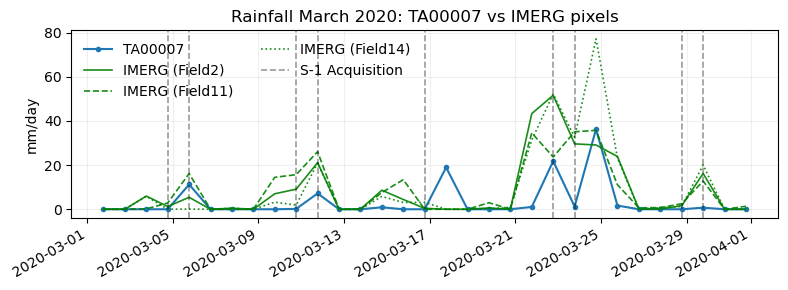

In [22]:
fig, ax = plt.subplots(figsize=(8, 3))

dates = pd.to_datetime([
    "2020-03-04", "2020-03-05", "2020-03-10",
    "2020-03-11", "2020-03-16", "2020-03-22",
    "2020-03-23", "2020-03-28", "2020-03-29"
])

# Station data (primary focus)
TA00007_daily = TA00007['precip_mm'].resample('D', offset='18H30min', label='right', closed='right').sum()

TA00007_march2020 = station_daily.loc['2020-03']
ax.plot(
    TA00007_march2020.index, TA00007_march2020.values,
     linewidth=1.5,
    marker='o', markersize=3, 
    label=station_name
)

imerg_halfhourly = xr.open_mfdataset(path_imerg_halfhourly)['precipitation']

# extract, resample, and store in dict
imerg_dict = {
    (i, j): imerg_halfhourly.isel(lat=i, lon=j)
                     .to_dataframe()['precipitation']
                     .resample('h', label='right', closed='right')
                     .sum()
    for i in range(3) for j in range(3)
}

# IMERG 
imerg_field2 = imerg_dict[(1,1)].resample(
    'D', offset='18H30min', label='right', closed='right'
).sum().loc['2020-03']

imerg_field11 = imerg_dict[(0,2)].resample(
    'D', offset='18H30min', label='right', closed='right'
).sum().loc['2020-03']

imerg_field14 = imerg_dict[(2,0)].resample(
    'D', offset='18H30min', label='right', closed='right'
).sum().loc['2020-03']

ax.plot(imerg_field2.index, imerg_field2.values,
        color='green', linewidth=1.2, alpha=0.9, label='IMERG (Field2)')

ax.plot(imerg_field11.index, imerg_field11.values,
        color='green', linewidth=1.2, alpha=0.9, linestyle='--', label='IMERG (Field11)')

ax.plot(imerg_field14.index, imerg_field14.values,
        color='green', linewidth=1.2, alpha=0.9, linestyle=':', label='IMERG (Field14)')

# Vertical lines (push to background)
dates_1830 = [pd.to_datetime(d).replace(hour=18, minute=30) for d in dates]

for i, date in enumerate(dates_1830):
    ax.axvline(
        date,
        color='black',
        linestyle='--',
        alpha=0.4,
        linewidth=1.2,
        label='S-1 Acquisition' if i == 0 else None
    )

ax.set_ylabel('mm/day')
ax.set_title('Rainfall March 2020: TA00007 vs IMERG pixels')

ax.grid(True, alpha=0.2)

ax.legend(frameon=False, fontsize=10, ncol=2)

fig.autofmt_xdate()
plt.tight_layout()

plt.show()

## Figure 13

Text(0.5, 0.33, 'Field14')

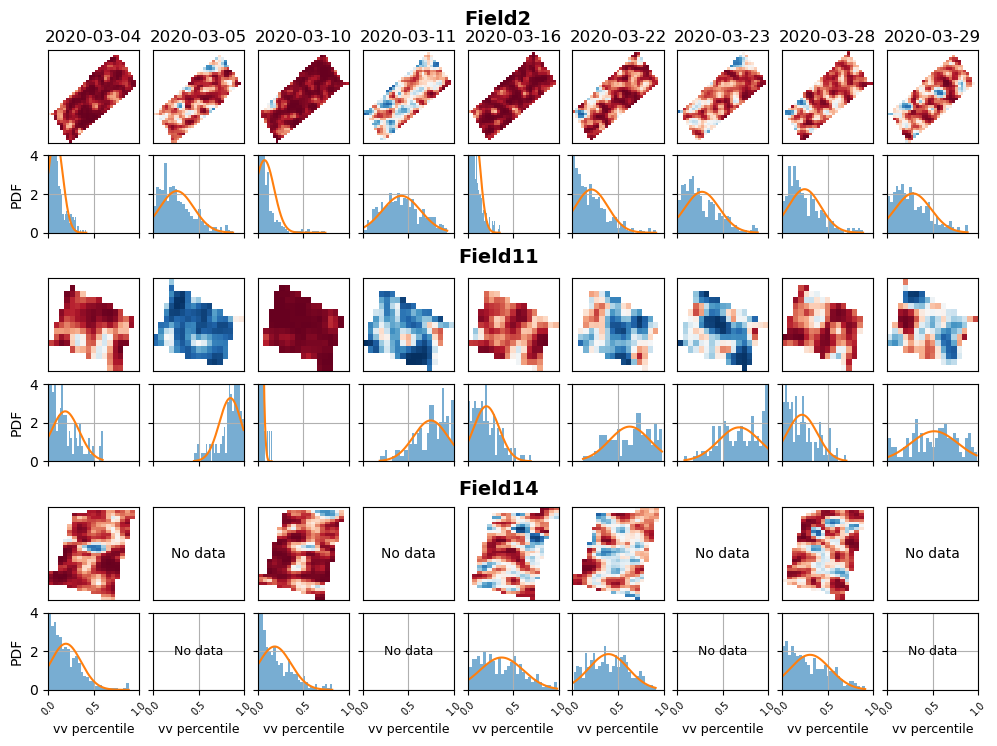

In [26]:
fields = ["Field2", "Field11", "Field14"]

dates = pd.to_datetime([
    "2020-03-04", "2020-03-05", "2020-03-10",
    "2020-03-11", "2020-03-16", "2020-03-22",
    "2020-03-23", "2020-03-28", "2020-03-29"
])


fig = plt.figure(figsize=(12, 8))

outer = gridspec.GridSpec(3, 9, wspace=0.15, hspace=0.25)

for r, field in enumerate(fields):

    ds = percentile_fields_dic[field]
    time_index = pd.to_datetime(ds["vv_percentile"].time.values)

    for c, date in enumerate(dates):

        inner = gridspec.GridSpecFromSubplotSpec(
            2, 1,
            subplot_spec=outer[r, c],
            height_ratios=[1.2, 1],
            hspace=0.15
        )

        # =========================
        # MAP
        # =========================
        ax_map = fig.add_subplot(inner[0])

        if date in time_index:
            da = ds["vv_percentile"].sel(time=date)
            da.plot(ax=ax_map, vmin=0, vmax=1, cmap="RdBu", add_colorbar=False)
        else:
            ax_map.text(0.5, 0.5, "No data",
                        ha="center", va="center")
            ax_map.set_xlim(0, 1)
            ax_map.set_ylim(0, 1)

        ax_map.set_xticks([])
        ax_map.set_yticks([])
        ax_map.set_xlabel('')
        ax_map.set_ylabel('')
        ax_map.set_title("")  


        if r == 0:
            ax_map.set_title(date.strftime("%Y-%m-%d")) 

        # =========================
        # PDF
        # =========================
        ax_pdf = fig.add_subplot(inner[1])

        if date in time_index:
            data = ds["vv_percentile"].sel(time=date).values
        else:
            data = np.array([])

        utils.plot_pdf(ax_pdf, data)

        ax_pdf.set_title("")   
        if c == 0:
            ax_pdf.set_ylabel('PDF')
            
        if c != 0:
            ax_pdf.grid(True)
            ax_pdf.set_yticklabels([])

        if r == 2:
            ax_pdf.grid(True)
            ax_pdf.set_xticks([0, 0.5, 1])  
            ax_pdf.set_xlabel('vv percentile', size=9)
            ax_pdf.tick_params(axis='x', rotation=45, labelsize=7)
        else:
            ax_pdf.grid(True)
            ax_pdf.xaxis.set_ticklabels([])

        
        
plt.subplots_adjust(bottom=0.08)
ax_pdf.tick_params(axis='x', rotation=45, labelsize=7)
fig.text(0.5, 0.93, "Field2", ha="center", va="top", fontsize=14, weight="bold")
fig.text(0.5, 0.62, "Field11", ha="center", va="center", fontsize=14, weight="bold")
fig.text(0.5, 0.33, "Field14", ha="center", va="center", fontsize=14, weight="bold")

## Tables

In [27]:

alpha = 0.005

field_names = [
    f"Field{i}" for i in range(1, 17)
]


def compute_ks_flag(data_prev1, data_prev2,
                    data_curr1, data_curr2,
                    alpha=0.005):

    def prep(d1, d2):
        mask = ~np.isnan(d1) & ~np.isnan(d2)
        return d1[mask], d2[mask]

    d1p, d2p = prep(data_prev1, data_prev2)
    d1c, d2c = prep(data_curr1, data_curr2)

    mean2p = np.mean(d2p)
    mean1c = np.mean(d1c)
    mean2c = np.mean(d2c)

    _, p_ks_prev = kstest(d2p, d1p, alternative='less')
    ks_stat, p_ks_curr = kstest(d2c, d1c, alternative='less')

    rel_curr = (
        (mean2c - mean1c) / mean1c
        if mean1c != 0 else np.nan
    )

    prev_ks_flag = p_ks_prev < alpha and mean2p > 0.2

    if prev_ks_flag:
        ks_sign = 0.5 if rel_curr > -0.1 and mean2c > 0.2 else 0
    else:
        ks_sign = 1 if p_ks_curr < alpha and mean2c > 0.2 else 0

    return ks_sign, ks_stat, p_ks_curr, rel_curr, mean2c


results = []

for field_id in field_names:

    ds = percentile_fields_dic[field_id]
    times = pd.to_datetime(ds.time.values)

    prev_persistent = False

    for t in range(2, len(times)):

        t_prev2 = times[t-2]
        t_prev1 = times[t-1]
        t_curr = times[t]

        data_prev1 = ds["vv_percentile"].sel(time=t_prev2).values.flatten()
        data_prev2 = ds["vv_percentile"].sel(time=t_prev1).values.flatten()

        data_curr1 = data_prev2
        data_curr2 = ds["vv_percentile"].sel(time=t_curr).values.flatten()

        ks_sign, ks_stat, ks_p, mean_delta, mean_percentile = compute_ks_flag(
            data_prev1, data_prev2,
            data_curr1, data_curr2,
            alpha=alpha
        )

        # Persistent rainfall condition
        if (
            prev_persistent
            and ks_sign == 0
            and mean_delta > -0.1
            and mean_percentile > 0.2
        ):
            ks_sign = 0.5

        prev_persistent = (ks_sign == 0.5)

        # Labels
        rain_flag = {
            1: "Yes",
            0.5: "Possible",
            0: "No"
        }[ks_sign]

        results.append({
            "Field ID": field_id,
            "Year": t_curr.year,
            "T1": t_prev1.strftime('%Y-%m-%d'),
            "T2": t_curr.strftime('%Y-%m-%d'),
            "KS Stat": ks_stat,
            "KS p-value": ks_p,
            "Significance": "Yes" if ks_p < alpha else "No",
            "Mean Delta": mean_delta,
            "Mean Percentile": mean_percentile,
            "Rain?": rain_flag
        })


# -------------------------------------------------
# FINAL DATAFRAME
# -------------------------------------------------

df_results = pd.DataFrame(results)

df_results[["KS Stat", "Mean Delta", "Mean Percentile"]] = (
    df_results[["KS Stat", "Mean Delta", "Mean Percentile"]].round(3)
)

df_results = df_results.sort_values(
    by=["Year", "T1", "Field ID"]
).reset_index(drop=True)

print(df_results)


C:\Users\vincenthoogela\AppData\Local\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\vincenthoogela\AppData\Local\anaconda3\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\12386171.py:24: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, p_ks_curr = kstest(d2c, d1c, alternative='less')
C:\Users\vincenthoogela\AppData\Local\Temp\ipykernel_26376\12386171.py:23: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  _, p_ks_prev = kstest(d2p, d1p, alternative='less')


     Field ID  Year          T1          T2  KS Stat    KS p-value  \
0     Field10  2016  2016-01-07  2016-01-14    0.068  1.312224e-01   
1     Field11  2016  2016-01-07  2016-01-14    0.109  2.424353e-01   
2     Field13  2016  2016-01-07  2016-01-14    0.000  1.000000e+00   
3     Field16  2016  2016-01-07  2016-01-14    0.050  2.852792e-01   
4      Field2  2016  2016-01-07  2016-01-14    0.005  9.905993e-01   
...       ...   ...         ...         ...      ...           ...   
9668   Field2  2026  2026-07-26  2026-07-27    0.012  9.409147e-01   
9669   Field2  2026  2026-07-27  2026-08-01    0.074  1.009721e-01   
9670   Field2  2026  2026-08-01  2026-08-02    0.200  3.614910e-08   
9671   Field2  2026  2026-08-02  2026-08-07    0.002  9.976415e-01   
9672   Field2  2026  2026-08-07  2026-08-08    0.007  9.792154e-01   

     Significance  Mean Delta  Mean Percentile     Rain?  
0              No      -0.139            0.337        No  
1              No       0.012            